<a href="https://colab.research.google.com/github/elijahschoeniger-cpu/Walmart-Project-1-/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics: Hurricane Helene, September 2024
### DS2002 Midterm Project · Team Case Crushers
**Sophie Li · Eli Schoeniger · AJ Amos**

We clean five messy Walmart data files, join them to real weather from the Open-Meteo API, and answer five questions about how Florida shoppers reacted to Hurricane Helene (landfall Sept 26, 2024). We end with a recommendation for Walmart leadership and a careful reflection from all the team members.

##1. Setup

In [ ]:
import os, time, sqlite3
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

# Get the data
!git clone https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git

# Hurricane Helene landfall date, used for the analysis windows and the charts
LANDFALL = pd.Timestamp('2024-09-26')

fatal: destination path 'Walmart-Project-1-' already exists and is not an empty directory.


## 2. Data loading, profile, and cleaning pipeline
**Owner: Eli**

We have five files: point-of-sale transactions (about 25,000 rows), store locations (14 rows), the product catalog (45 SKUs), distribution centers (5 rows), and a SQLite database with `daily_sales_summary` and `inventory_levels`. Every file has quality problems on purpose.

The cell below loads everything, profiles the raw transactions and stores to show the mess, then cleans each table step by step. Every decision is written to the decision log.

###2.0 Paths, database connection, and decision log
Sets up the data path, the database connection, the decision log, and the `profile()` function.

In [ ]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary

REPO_PATH = globals().get('REPO_PATH', '/content/Walmart-Project-1-/')
DATA = os.path.join(REPO_PATH, 'data')

conn = sqlite3.connect(os.path.join(DATA, 'inventory_and_sales.db'))
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))

DECISIONS = []
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)


                  name
0  daily_sales_summary
1     inventory_levels


###2.1 Load and profile the raw data
Every file is read as text so nothing gets converted by guessing; the profile shows the mess before any cleaning.



In [ ]:
# Read everything as text so pandas doesn't guess types; we convert explicitly.
NA_TOKENS = ['', 'NULL', 'N/A', 'NaN', 'nan', 'NA', 'None']
raw_txn = pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv'), dtype=str,
                      keep_default_na=False)
raw_stores  = pd.read_csv(os.path.join(DATA, 'store_locations.csv'), dtype=str, keep_default_na=False)
raw_catalog = pd.read_csv(os.path.join(DATA, 'product_catalog.csv'), dtype=str, keep_default_na=False)
raw_dc      = pd.read_csv(os.path.join(DATA, 'distribution_centers.csv'), dtype=str, keep_default_na=False)
raw_sales   = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
raw_inv     = pd.read_sql_query('SELECT * FROM inventory_levels', conn)

# Profile the files read the default way, so blanks/NULL/N/A count as missing
profile(pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv')), 'walmart_transactions')
profile(pd.read_csv(os.path.join(DATA, 'store_locations.csv')), 'store_locations')

=== walmart_transactions ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30
=== store_locations ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id     object      0       0.0        14
store_name   object      0       0.0        12
city         object      0       0.0        12
state        object      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1       7.1        11
region       object      0       0.0         7

e

,dtype,nulls,null_pct,distinct
store_id,object,0,0.0,14
store_name,object,0,0.0,12
city,object,0,0.0,12
state,object,0,0.0,3
zip_code,int64,0,0.0,12
latitude,float64,1,7.1,11
longitude,float64,1,7.1,11
region,object,0,0.0,7


###2.2 Shared helpers and lookup tables (SKUs Consolidation)
Shared cleaning functions plus the SKU map (45 SKUs → 20 products) and category map (37 spellings → 10).

In [ ]:
def to_na(s):
    """Strip whitespace and turn every missing-value spelling into a real NaN."""
    s = s.astype(str).str.strip()
    return s.mask(s.isin(NA_TOKENS))

def norm_store_id(s):
    """' FL-330', 'fl_330', 'FL330' -> 'FL-330'."""
    return (s.astype(str).str.strip().str.upper()
             .str.replace(r'^FL[\s_-]?(\d{3})$', r'FL-\1', regex=True))

# 45 SKUs collapse to 20 real products (verified: every SKU's names are variants of one item)
SKU_TO_PRODUCT = {
    'PT-12': 'PT-STRAW', 'SKU#459812': 'PT-STRAW', 'POPTART-STRAW': 'PT-STRAW', 'PT_STRAWBERRY': 'PT-STRAW',
    'WTR-24': 'WATER-24', 'WATER24PK': 'WATER-24', 'WTR_24PK': 'WATER-24',
    'BATT-100': 'BATT-AA4', 'BAT-AA4': 'BATT-AA4', 'BATT_AA_4PK': 'BATT-AA4',
    'FLASH-01': 'FLASHLIGHT', 'LED-FLASH': 'FLASHLIGHT',
    'BEER-24': 'BEER-24', 'LTBEER24': 'BEER-24',
    'BG-MONO': 'MONOPOLY', 'MONOPOLY-01': 'MONOPOLY', 'GAME-MONO': 'MONOPOLY',
    'CARDS-01': 'CARDS', 'PLAYCARD-STD': 'CARDS',
    'STREAM-01': 'STREAMING', 'ROKU-STD': 'STREAMING',
    'SOUP-CAN': 'SOUP', 'CNSOUP-01': 'SOUP',
    'BREAD-WH': 'BREAD', 'WHITEBREAD': 'BREAD',
    'PB-16': 'PB-16', 'PNUTBTR-16': 'PB-16',
    'CNDL-EM': 'CANDLES', 'CANDLE-EMRG': 'CANDLES',
    'FAID-01': 'FIRSTAID', 'FIRSTAID-KIT': 'FIRSTAID',
    'CHRG-PORT': 'CHARGER', 'PORTCHARGER': 'CHARGER',
    'CHIPS-VP': 'CHIPS-VP', 'CHIPVARIETY': 'CHIPS-VP',
    'PTOWEL-6': 'PTOWEL-6', 'PAPERTOWEL6': 'PTOWEL-6',
    'TP-12': 'TP-12', 'TOILETPAPER12': 'TP-12',
    'DIAP-S3': 'DIAPERS-3', 'DIAPERS-3': 'DIAPERS-3',
    'BFORM-01': 'FORMULA', 'BABYFORMULA': 'FORMULA',
    'TARP-HD': 'TARP', 'HDTARP-01': 'TARP',
}
PRODUCTS = pd.DataFrame([
    ('PT-STRAW',  'Pop-Tarts Strawberry',     'Breakfast'),
    ('WATER-24',  'Bottled Water 24-Pack',    'Emergency'),
    ('BATT-AA4',  'AA Batteries 4-Pack',      'Emergency'),
    ('FLASHLIGHT','LED Flashlight',           'Emergency'),
    ('CANDLES',   'Emergency Candles',        'Emergency'),
    ('TARP',      'Heavy Duty Tarp',          'Emergency'),
    ('BEER-24',   'Light Beer 24-Pack',       'Alcohol'),
    ('MONOPOLY',  'Monopoly Board Game',      'Entertainment'),
    ('CARDS',     'Playing Cards',            'Entertainment'),
    ('STREAMING', 'Roku Streaming Stick',     'Electronics'),
    ('CHARGER',   'Portable Phone Charger',   'Electronics'),
    ('SOUP',      'Canned Soup',              'Grocery'),
    ('BREAD',     'White Bread',              'Grocery'),
    ('PB-16',     'Peanut Butter 16oz',       'Grocery'),
    ('FIRSTAID',  'First Aid Kit',            'Health'),
    ('CHIPS-VP',  'Chips Variety Pack',       'Snacks'),
    ('PTOWEL-6',  'Paper Towels 6-Roll',      'Household'),
    ('TP-12',     'Toilet Paper 12-Roll',     'Household'),
    ('DIAPERS-3', 'Diapers Size 3',           'Baby'),
    ('FORMULA',   'Baby Formula',             'Baby'),
], columns=['product_id', 'product', 'category_clean'])

# Messy category text -> the same 10 categories the database already uses
CATEGORY_MAP = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}
def norm_category(s):
    return s.astype(str).str.strip().str.lower().map(CATEGORY_MAP)

###2.3 Clean transactions
Only exact duplicates are removed; missing timestamps and returns are kept and flagged.

In [ ]:
txn = raw_txn.copy()
n0 = len(txn)

# 2a. exact duplicates
dups = txn.duplicated().sum()
txn = txn.drop_duplicates().reset_index(drop=True)
log('txn_duplicates', 'Dropped exact duplicate rows (dup transaction_ids were all exact copies)', dups)
assert txn.transaction_id.is_unique

# 2b. store ids
before = txn.store_id.copy()
txn['store_id'] = norm_store_id(txn.store_id)
log('txn_store_id', "Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash)",
    (before != txn.store_id).sum())
assert txn.store_id.str.fullmatch(r'FL-\d{3}').all() and txn.store_id.nunique() == 12

# 2c. timestamps — 5 formats; parse each explicitly so nothing gets guessed wrong
ts = to_na(txn.timestamp)
n_missing_ts = ts.isna().sum()
FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
           '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']
parsed = pd.Series(pd.NaT, index=ts.index, dtype='datetime64[ns]')
for fmt in FORMATS:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
unparsed = (ts.notna() & parsed.isna()).sum()
assert unparsed == 0, f'{unparsed} timestamps matched no known format'
txn['timestamp'] = parsed
log('txn_timestamp', 'Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime', len(txn) - n_missing_ts)
log('txn_timestamp_missing', "Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing",
    n_missing_ts)
txn['ts_missing'] = txn.timestamp.isna()
assert txn.timestamp.dropna().between('2024-09-01', '2024-10-01').all()

# Timezone: POS times are local store time. Pensacola (FL-710) is in Central time; every other store is Eastern.
# timestamp_utc is what to join to the weather API data.
CENTRAL = {'FL-710'}
txn['tz'] = np.where(txn.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
txn['timestamp_utc'] = pd.concat([
    g.timestamp.dt.tz_localize(tz, ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
    for tz, g in txn.groupby('tz')
]).sort_index()
log('txn_timezone', 'Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join',
    txn.timestamp_utc.notna().sum())
txn['date'] = txn.timestamp.dt.normalize()
txn['hour'] = txn.timestamp.dt.hour

# 2d. prices: '$8.26', ' 3.43 ' -> 8.26, 3.43
txn['unit_price'] = pd.to_numeric(txn.unit_price.str.replace(r'[$,\s]', '', regex=True), errors='raise')
log('txn_unit_price', "Stripped '$' and whitespace from unit_price, cast to float",
    raw_txn.unit_price.str.contains(r'[$\s]', regex=True).sum())

# 2e. quantity + negatives
txn['quantity'] = pd.to_numeric(txn.quantity, errors='raise').astype(int)
txn['is_return'] = txn.quantity < 0
log('txn_negative_qty', 'Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0',
    txn.is_return.sum())
txn['line_total'] = (txn.quantity * txn.unit_price).round(2)

# 2f. SKUs -> canonical product; categories from the product (not the messy text)
txn['sku'] = txn.sku.str.strip()
txn['product_id'] = txn.sku.map(SKU_TO_PRODUCT)
assert txn.product_id.notna().all(), 'unmapped SKU'
txn = txn.merge(PRODUCTS, on='product_id', how='left')
log('txn_sku_consolidation', f'Mapped {txn.sku.nunique()} SKUs / {raw_txn.product_name.nunique()} name variants -> {txn.product_id.nunique()} products',
    len(txn))

cat_from_text = norm_category(txn.category)
mismatch = (cat_from_text != txn.category_clean).sum()
assert cat_from_text.notna().all(), 'unmapped category spelling'
log('txn_category', f'Collapsed {raw_txn.category.nunique()} category spellings -> 10; product-derived category disagrees with text in {mismatch} rows',
    len(txn))
txn = txn.rename(columns={'product_name': 'product_name_raw', 'category': 'category_raw'})
txn = txn.rename(columns={'category_clean': 'category'})

print(f'\ntransactions: {n0:,} -> {len(txn):,} rows')
txn.head()

[txn_duplicates] Dropped exact duplicate rows (dup transaction_ids were all exact copies) (30 row(s))
[txn_store_id] Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash) (4345 row(s))
[txn_timestamp] Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime (24648 row(s))
[txn_timestamp_missing] Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing (884 row(s))
[txn_timezone] Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join (24648 row(s))
[txn_unit_price] Stripped '$' and whitespace from unit_price, cast to float (4332 row(s))
[txn_negative_qty] Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0 (130 row(s))
[txn_sku_consolidation] Mapped 45 SKUs / 63 name variants -> 20 products (25532 row(s))
[txn_category] Collapsed 37 category spellings -> 10; product-derived category disagrees wit

,transaction_id,store_id,timestamp,sku,product_name_raw,category_raw,quantity,unit_price,ts_missing,tz,timestamp_utc,date,hour,is_return,line_total,product_id,product,category
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,America/Chicago,2024-09-24 14:48:13+00:00,2024-09-24,9.0,False,3.15,PB-16,Peanut Butter 16oz,Grocery
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,False,America/New_York,2024-09-14 00:30:20+00:00,2024-09-13,20.0,False,2.02,SOUP,Canned Soup,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,False,America/New_York,2024-09-17 14:06:00+00:00,2024-09-17,10.0,False,20.94,TP-12,Toilet Paper 12-Roll,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,False,America/New_York,2024-09-11 10:29:08+00:00,2024-09-11,6.0,False,28.59,STREAMING,Roku Streaming Stick,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,False,America/New_York,2024-09-26 19:59:42+00:00,2024-09-26,15.0,False,56.46,BEER-24,Light Beer 24-Pack,Alcohol


### 2.4 Clean store locations
Two duplicate stores removed and the missing Tallahassee coordinates filled in, leaving 12 stores that match the transactions.

In [ ]:
stores = raw_stores.copy()
stores['store_id'] = norm_store_id(stores.store_id)
for c in stores.columns:
    stores[c] = to_na(stores[c])
dups = stores.duplicated('store_id').sum()
stores = stores.drop_duplicates('store_id').reset_index(drop=True)
log('stores_duplicates', "Dropped duplicate stores that only differed by id format (FL239, FL_287)", dups)

bad_state = (stores.state != 'FL').sum()
stores['state'] = 'FL'
log('stores_state', "Standardized state ('Florida', 'Fla.') -> 'FL'", bad_state)

stores['zip_code'] = stores.zip_code.str.zfill(5)
stores[['latitude', 'longitude']] = stores[['latitude', 'longitude']].astype(float)
miss = stores.latitude.isna()
# Tallahassee city-center coordinates — needed for the weather API call and the map
stores.loc[stores.store_id == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
log('stores_coords', 'Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup)', miss.sum())

stores['region'] = stores.region.str.strip().str.title()
stores['tz'] = np.where(stores.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
assert stores.store_id.nunique() == 12 and set(stores.store_id) == set(txn.store_id)
stores


[stores_duplicates] Dropped duplicate stores that only differed by id format (FL239, FL_287) (2 row(s))
[stores_state] Standardized state ('Florida', 'Fla.') -> 'FL' (3 row(s))
[stores_coords] Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup) (1 row(s))


,store_id,store_name,city,state,zip_code,latitude,longitude,region,tz
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West,America/New_York
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South,America/New_York
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North,America/New_York
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central,America/New_York
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East,America/New_York
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West,America/New_York
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North,America/New_York
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,30.4383,-84.2807,Panhandle,America/New_York
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,FL,33701,27.7676,-82.6403,West,America/New_York


### 2.5 Clean product catalog
Missing unit costs filled with the same product's median cost; supplier and package size are unreliable, so we don't use them.

In [ ]:
catalog = raw_catalog.copy()
for c in catalog.columns:
    catalog[c] = to_na(catalog[c])
catalog['product_id'] = catalog.sku.map(SKU_TO_PRODUCT)
assert catalog.product_id.notna().all()
catalog = catalog.merge(PRODUCTS, on='product_id', how='left')
catalog['category_raw'] = catalog.pop('category')
catalog = catalog.rename(columns={'category_clean': 'category', 'product_name': 'product_name_raw'})

catalog['unit_cost'] = pd.to_numeric(catalog.unit_cost)
miss = catalog.unit_cost.isna()
catalog['unit_cost_imputed'] = miss
catalog['unit_cost'] = catalog.unit_cost.fillna(catalog.groupby('product_id').unit_cost.transform('median'))
log('catalog_unit_cost', 'Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed', miss.sum())
log('catalog_supplier_pkg', 'supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze', len(catalog))
catalog


[catalog_unit_cost] Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed (5 row(s))
[catalog_supplier_pkg] supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze (45 row(s))


,sku,product_name_raw,subcategory,unit_cost,supplier,package_size,product_id,product,category,category_raw,unit_cost_imputed
0,PT-12,pop-tarts strawberry,NaN,1.930,Johnson & Johnson,4-pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast Foods,False
1,SKU#459812,Strawberry Pop-Tart,Pop-Tarts,2.260,Roku Inc,4pk,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
2,POPTART-STRAW,Pop-Tarts Strawberry,NaN,2.110,Sara Lee,6 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
3,PT_STRAWBERRY,pop-tarts strawberry,Pop-Tarts,2.110,Campbell's,4 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,breakfast,True
4,WTR-24,BOTTLED WATER 24PK,Bottled,2.640,Sara Lee,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency Supplies,False
5,WATER24PK,Bottled Water 24-Pack,Bottled,2.380,Sara Lee,24 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
6,WTR_24PK,Water - 24 Pack,NaN,2.080,Frito-Lay,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
7,BATT-100,BATTERIES AA 4PK,AA,3.935,3M Company,6 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,True
8,BAT-AA4,AA Batteries 4-Pack,AA,4.160,Kimberly-Clark,4pk,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,False
9,BATT_AA_4PK,AA Batteries 4-Pack,AA,3.710,Anheuser-Busch,24 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency,False


### 2.6 Clean distribution centers
Converted text numbers to real numbers; one missing shipping cost is left blank since 5 rows aren't enough to estimate it.

In [ ]:
dc = raw_dc.copy()
for c in dc.columns:
    dc[c] = to_na(dc[c])
dc['surge_capacity_approx'] = dc.surge_capacity.str.contains('~', na=False)
dc['surge_capacity'] = pd.to_numeric(dc.surge_capacity.str.replace('~', '', regex=False))
log('dc_surge_capacity', "Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx", dc.surge_capacity_approx.sum())
for c in ['avg_daily_shipments', 'distance_to_orlando_mi', 'cost_per_shipment']:
    dc[c] = pd.to_numeric(dc[c])
log('dc_cost_missing', 'DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows)',
    dc.cost_per_shipment.isna().sum())
dc


[dc_surge_capacity] Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx (1 row(s))
[dc_cost_missing] DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows) (1 row(s))


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment,surge_capacity_approx
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0,False
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5,False
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0,False
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0,True
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN,False


### 2.7 Clean database tables
Problems that could matter for Q5 (fractional units, negative revenue, unknown SKUs) are flagged, not deleted.

In [ ]:
sales = raw_sales.copy()
compact = sales.date.str.fullmatch(r'\d{8}')
sales['date'] = pd.to_datetime(sales.date, format='%Y-%m-%d', errors='coerce').fillna(
                pd.to_datetime(sales.date, format='%Y%m%d', errors='coerce'))
assert sales.date.notna().all()
log('db_sales_date', "daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime", compact.sum())
sales['store_id'] = norm_store_id(sales.store_id)
sales['category'] = norm_category(sales.category)
assert sales.category.notna().all()
dups = sales.duplicated(['date', 'store_id', 'category']).sum()
sales = sales.drop_duplicates(['date', 'store_id', 'category']).reset_index(drop=True)
log('db_sales_duplicates', 'daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped', dups)

sales['units_fractional'] = sales.total_units % 1 != 0
sales['revenue_negative'] = sales.total_revenue < 0
log('db_sales_fractional', 'daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5',
    sales.units_fractional.sum())
log('db_sales_negative', 'daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5',
    sales.revenue_negative.sum())

inv = raw_inv.copy()
inv['date'] = pd.to_datetime(inv.date)
inv['store_id'] = norm_store_id(inv.store_id)
inv['product_id'] = inv.sku.map(SKU_TO_PRODUCT)
orphans = inv.product_id.isna()
inv['orphan_sku'] = orphans   # kept for Q5: possible SKU miscoding (e.g. LEGACY-PT)
log('db_inv_orphan_skus', f'inventory_levels: SKUs not in catalog {sorted(inv.loc[orphans, "sku"].unique())} — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis)', orphans.sum())
log('db_inv_on_order', 'inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0)',
    inv.units_on_order.isna().sum())
inv['below_reorder'] = inv.units_on_hand < inv.reorder_point



[db_sales_date] daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime (218 row(s))
[db_sales_duplicates] daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped (0 row(s))
[db_sales_fractional] daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5 (76 row(s))
[db_sales_negative] daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5 (34 row(s))
[db_inv_orphan_skus] inventory_levels: SKUs not in catalog ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis) (355 row(s))
[db_inv_on_order] inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0) (626 row(s))


### 2.8 Final checks and save
Confirms every store ID and category lines up across files before the analysis starts.

In [ ]:
assert txn.store_id.isin(stores.store_id).all()
assert sales.store_id.isin(stores.store_id).all() and inv.store_id.isin(stores.store_id).all()
assert set(txn.category) == set(sales.category)

OUT = os.path.join(DATA, 'clean')
os.makedirs(OUT, exist_ok=True)
txn.to_csv(os.path.join(OUT, 'transactions_clean.csv'), index=False)
stores.to_csv(os.path.join(OUT, 'stores_clean.csv'), index=False)
catalog.to_csv(os.path.join(OUT, 'catalog_clean.csv'), index=False)
PRODUCTS.to_csv(os.path.join(OUT, 'products.csv'), index=False)
dc.to_csv(os.path.join(OUT, 'distribution_centers_clean.csv'), index=False)
sales.to_csv(os.path.join(OUT, 'daily_sales_clean.csv'), index=False)
inv.to_csv(os.path.join(OUT, 'inventory_clean.csv'), index=False)
print('saved to', OUT)

saved to /content/Walmart-Project-1-/data/clean


## 3. Decision log, cleaned tables and shape check
**Owner: Eli (Decision log + cleaned tables) + Sophie (shape check)**

The decision log lists every cleaning step, what it did, and how many rows it touched. Below it, a short guide to the cleaned tables and the new columns we added, since the analysis filters on them throughout.

We end with a shape check - daily orders after cleaning. If the pipeline had a bug, it would usually show up here as a day at zero or a day at ten times normal.

###3.1 Decision log

In [ ]:
pd.set_option('display.max_colwidth', None)   # show each decision in full
show_log()

,step,decision,rows
0,txn_duplicates,Dropped exact duplicate rows (dup transaction_ids were all exact copies),30
1,txn_store_id,"Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash)",4345
2,txn_timestamp,"Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime",24648
3,txn_timestamp_missing,"Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing",884
4,txn_timezone,"Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join",24648
5,txn_unit_price,"Stripped '$' and whitespace from unit_price, cast to float",4332
6,txn_negative_qty,"Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0",130
7,txn_sku_consolidation,Mapped 45 SKUs / 63 name variants -> 20 products,25532
8,txn_category,Collapsed 37 category spellings -> 10; product-derived category disagrees with text in 0 rows,25532
9,stores_duplicates,"Dropped duplicate stores that only differed by id format (FL239, FL_287)",2


###3.2 Cleaned tables - Can everyone please check this and delete this once finish - SL

| Table | What it is | Key columns we added |
|---|---|---|
| `txn` | Cleaned transactions | `date` (local day), `ts_missing` (no timestamp, excluded from time analysis), `is_return` (negative quantity, excluded from demand), `product_id` (canonical product after SKU merge), `line_total` |
| `stores` | 12 stores with coordinates | `tz` (FL-710 is Central time) |
| `sales` | Database daily sales summary | `units_fractional`, `revenue_negative` (flagged for Q5) |
| `inv` | Database inventory levels | `below_reorder`, `orphan_sku` (flagged for Q5) |
| `weather_live` | Open-Meteo daily weather, Orlando | `source` (live API or fallback) |

###3.3 Shape check - Chart 1

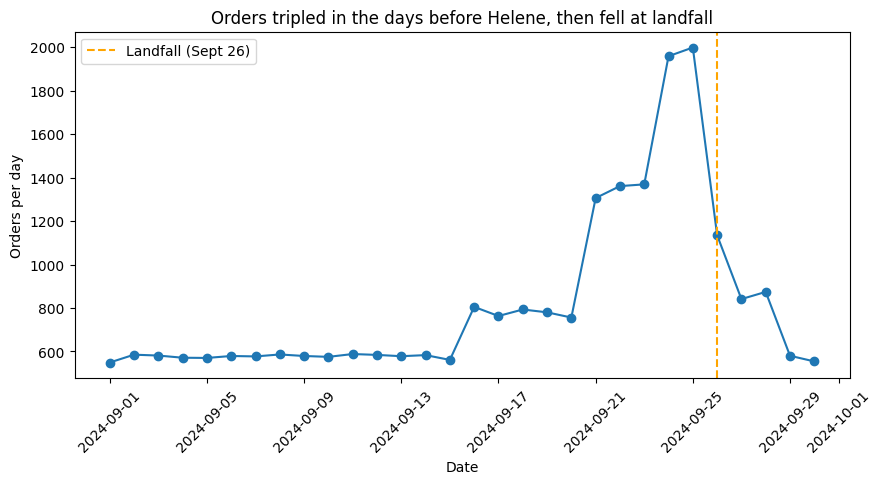

days with zero orders: 0
peak day vs Sept 1-15 baseline: 3.5 x


In [ ]:
# Cleaned transactions: keep rows with a timestamp, skip returns
t = txn[~txn['ts_missing'] & ~txn['is_return']]
daily = t.groupby('date')['transaction_id'].nunique()

plt.figure(figsize=(10, 4.5))
plt.plot(daily.index, daily.values, marker='o')
plt.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
plt.xlabel('Date')
plt.ylabel('Orders per day')
plt.title('Orders tripled in the days before Helene, then fell at landfall')
plt.legend()
plt.xticks(rotation=45)
plt.show()

# A day at zero or ~10x normal would point to a pipeline bug
baseline = daily[daily.index <= '2024-09-15'].median()
print('days with zero orders:', (daily == 0).sum())
print('peak day vs Sept 1-15 baseline:', round(daily.max() / baseline, 1), 'x')

## 4. Weather API and join
**Owner: AJ**

We pull daily weather for Orlando (28.54, -81.38) from the Open-Meteo Historical Weather API (base URL: `https://archive-api.open-meteo.com/v1/archive`). The call retries on rate limits and server errors, and every row has a `source` column so a saved fallback copy is never mistaken for live data.

Weather is requested in `America/New_York` time, so each day lines up with the local sales `date`. Assume that all data has been previously cleaned.

###4.1 API Call

In [ ]:
# Read data from loaded files as a check that we are reading clean data
OUT = os.path.join(DATA, 'clean')
assert os.path.isdir(OUT)
print(f"READING CLEAN DATA THAT WAS JUST WRITTEN TO {OUT}")
txn_clean = pd.read_csv(os.path.join(OUT, 'transactions_clean.csv'))
stores_clean = pd.read_csv(os.path.join(OUT, 'stores_clean.csv'))
catalog_clean = pd.read_csv(os.path.join(OUT, 'catalog_clean.csv'))
PRODUCTS_clean = pd.read_csv(os.path.join(OUT, 'products.csv'))
dc_clean = pd.read_csv(os.path.join(OUT, 'distribution_centers_clean.csv'))
sales_clean = pd.read_csv(os.path.join(OUT, 'daily_sales_clean.csv'))
inv_clean = pd.read_csv(os.path.join(OUT, 'inventory_clean.csv'))


READING CLEAN DATA THAT WAS JUST WRITTEN TO /content/Walmart-Project-1-/data/clean


In [ ]:
# Connect to open-meteo
import requests

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    # Get all relevant data from API
    weather_live = pd.merge(sales_clean, stores_clean, on='store_id', how='left')
    unique_locations = weather_live[['latitude', 'longitude']].drop_duplicates().dropna()
    weather_dfs = []
    # Iterate over each unique store
    for _, row in unique_locations.iterrows():
        lat, lon = row['latitude'], row['longitude']

        # Get date range specific to this location
        loc_mask = (weather_live['latitude'] == lat) & (weather_live['longitude'] == lon)
        min_date = weather_live.loc[loc_mask, 'date'].min()
        max_date = weather_live.loc[loc_mask, 'date'].max()

        # Fetch weather data for store location
        df_weather = daily_weather(min_date, max_date, lat=lat, lon=lon)
        df_weather['latitude'] = lat
        df_weather['longitude'] = lon
        weather_dfs.append(df_weather)

    all_weather = pd.concat(weather_dfs, ignore_index=True)
    # Prepare for merging
    weather_live['date'] = pd.to_datetime(weather_live['date'])

    # Merge weather data based on date, latitude, and longitude
    weather_live = pd.merge(
        weather_live,
        all_weather[['date', 'latitude', 'longitude', 'precipitation_sum', 'windspeed_10m_max', 'source']],
        on=['date', 'latitude', 'longitude'],
        how='left'
    )
    weather_live['precipitation_sum'] = weather_live['precipitation_sum'].fillna(-1)
    weather_live['windspeed_10m_max'] = weather_live['windspeed_10m_max'].fillna(-1)


except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

print('source:', weather_live['source'].iloc[0])

print(f"Num of Rows Before Merge in Sales: {len(sales_clean)}")
print(f"Num of Rows After Merge with Weather: {len(weather_live)}")
if (weather_live['precipitation_sum'].isin([-1]).any() or weather_live['precipitation_sum'].isin([-1]).any()):
  print("Weather data not present for all dates")
else:
  print("Weather data present for all dates")
weather_live.head()

source: open-meteo
Num of Rows Before Merge in Sales: 3600
Num of Rows After Merge with Weather: 3600
Weather data present for all dates


,date,store_id,category,total_units,total_revenue,units_fractional,revenue_negative,store_name,city,state,zip_code,latitude,longitude,region,tz,precipitation_sum,windspeed_10m_max,source
0,2024-09-12,FL-239,Emergency,90.0,1582.55,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,0.8,11.9,open-meteo
1,2024-09-12,FL-239,Breakfast,57.0,356.99,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,0.8,11.9,open-meteo
2,2024-09-12,FL-239,Alcohol,41.0,246.65,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,0.8,11.9,open-meteo
3,2024-09-12,FL-239,Entertainment,53.0,916.56,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,0.8,11.9,open-meteo
4,2024-09-12,FL-239,Grocery,69.0,339.30,False,False,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York,0.8,11.9,open-meteo


In [ ]:
log('weather-api', 'Deciding to merge all relevant weather data inside weather_live dataset. Large dataset will be used in the following cells',
    weather_live.head())

[weather-api] Deciding to merge all relevant weather data inside weather_live dataset. Large dataset will be used in the following cells (        date store_id       category  total_units  total_revenue  \
0 2024-09-12   FL-239      Emergency         90.0        1582.55   
1 2024-09-12   FL-239      Breakfast         57.0         356.99   
2 2024-09-12   FL-239        Alcohol         41.0         246.65   
3 2024-09-12   FL-239  Entertainment         53.0         916.56   
4 2024-09-12   FL-239        Grocery         69.0         339.30   

   units_fractional  revenue_negative                   store_name     city  \
0             False             False  Walmart Supercenter Orlando  Orlando   
1             False             False  Walmart Supercenter Orlando  Orlando   
2             False             False  Walmart Supercenter Orlando  Orlando   
3             False             False  Walmart Supercenter Orlando  Orlando   
4             False             False  Walmart Supercenter

###4.2 Charting and Data Exploring

Taking large dataset merged with weather API data and analyzing.

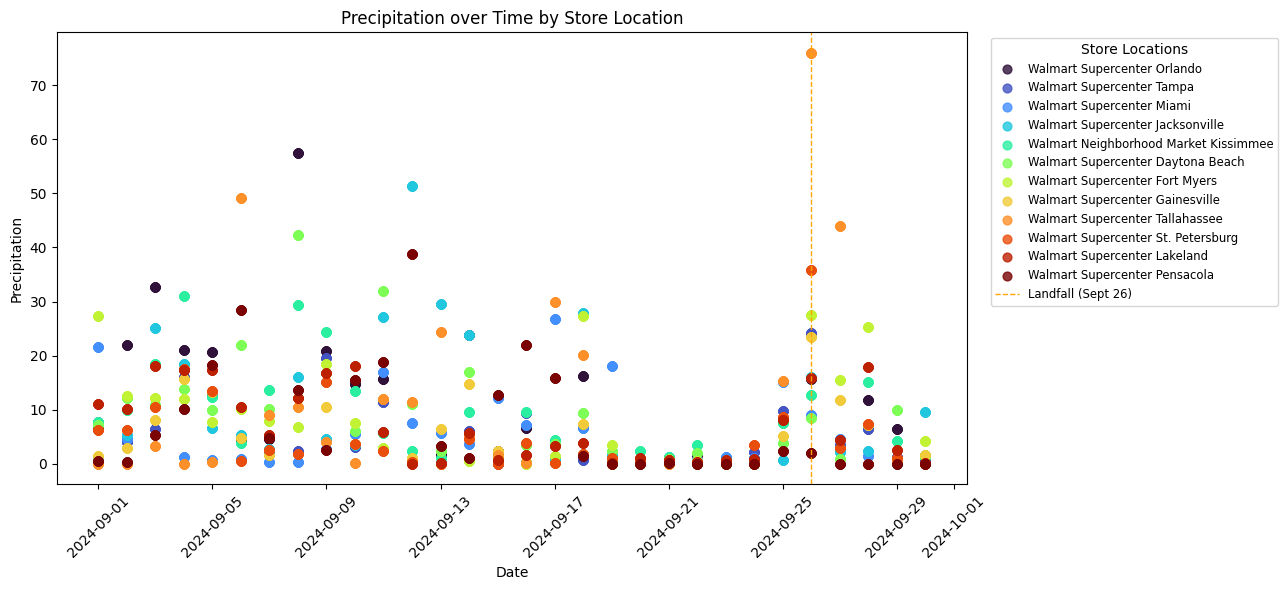

Highest Rainfall on Landfall (2024-09-26):
  Store ID:   FL-619
  Store Name: Walmart Supercenter Tallahassee
  Rainfall:   76.0


In [ ]:
# Graphing weather data alongside sales (Chart 2)
# Get unique stores
unique_stores = weather_live['store_id'].unique()
num_stores = len(unique_stores)

# Generate distinct colors across the entire spectrum using a colormap ('turbo' or 'tab20')
colors = plt.cm.turbo(np.linspace(0, 1, num_stores))

plt.figure(figsize=(13, 6))

# Plot each store with its distinct color and label
for store_id, color in zip(unique_stores, colors):
    subset = weather_live[weather_live['store_id'] == store_id]

    store_name = subset['store_name'].iloc[0]

    plt.scatter(
        subset['date'],
        subset['precipitation_sum'],
        color=color,
        label=store_name,
        alpha=0.8,
        s=40
    )

# Landfall reference line
plt.axvline(LANDFALL, color='orange', linestyle='--', linewidth=1, label='Landfall (Sept 26)')

plt.xlabel('Date')
plt.ylabel('Precipitation')
plt.title('Precipitation over Time by Store Location')
plt.xticks(rotation=45)

# Automatically adjust legend columns based on store count so it fits vertically
num_cols = 1 if num_stores <= 15 else (2 if num_stores <= 35 else 3)

# Position legend outside the plot frame on the right
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=num_cols,
    fontsize='small',
    title="Store Locations"
)

plt.tight_layout()
plt.show()

# Print Store with highest rainfall on landfall day
landfall_date = pd.to_datetime(LANDFALL)
landfall_df = weather_live[weather_live['date'] == landfall_date]
max_rain_row = landfall_df.loc[landfall_df['precipitation_sum'].idxmax()]

store_name_col = next((col for col in ['store_name', 'name', 'store'] if col in max_rain_row.index), None)
store_name = max_rain_row[store_name_col] if store_name_col else f"Store #{max_rain_row['store_id']}"

print(f"Highest Rainfall on Landfall ({landfall_date.strftime('%Y-%m-%d')}):")
print(f"  Store ID:   {max_rain_row['store_id']}")
print(f"  Store Name: {store_name}")
print(f"  Rainfall:   {max_rain_row['precipitation_sum']}")


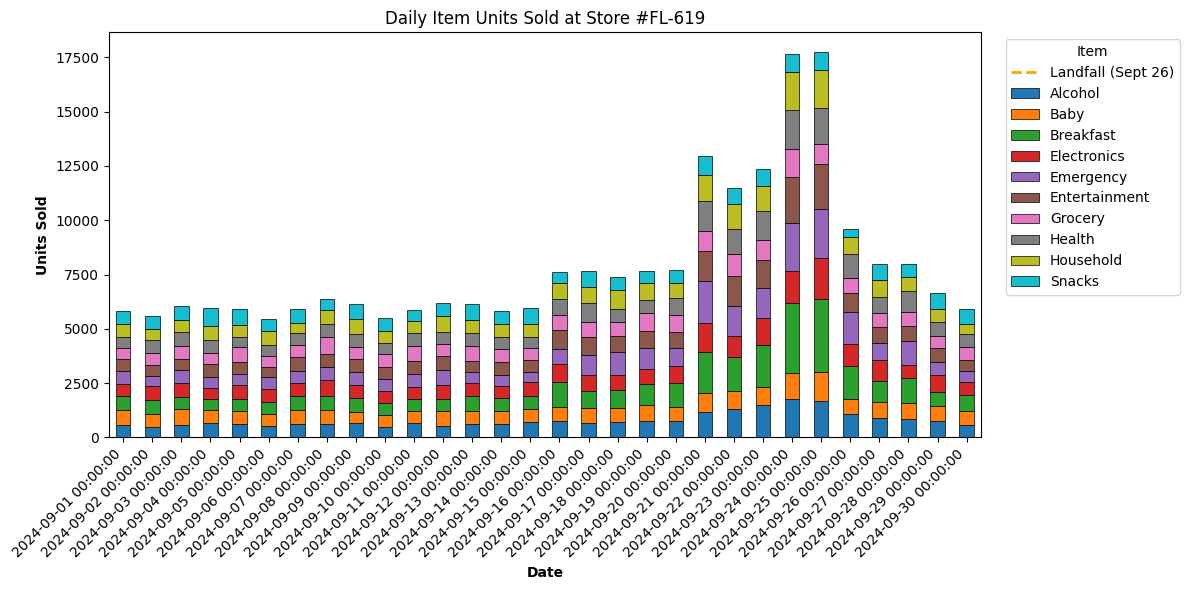

In [ ]:
# Pivot data so rows are dates and columns are items
store_pivot = weather_live.pivot_table(
    index='date',
    columns='category',
    values='total_units',
    aggfunc='sum',
    fill_value=0
)

# Plot stacked bar chart across dates (Chart 3)
ax = store_pivot.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab10', edgecolor='black', linewidth=0.5)

plt.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

plt.xlabel('Date', fontweight='bold')
plt.ylabel('Units Sold', fontweight='bold')
plt.title(f'Daily Item Units Sold at Store #{max_rain_row['store_id']}', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Item', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

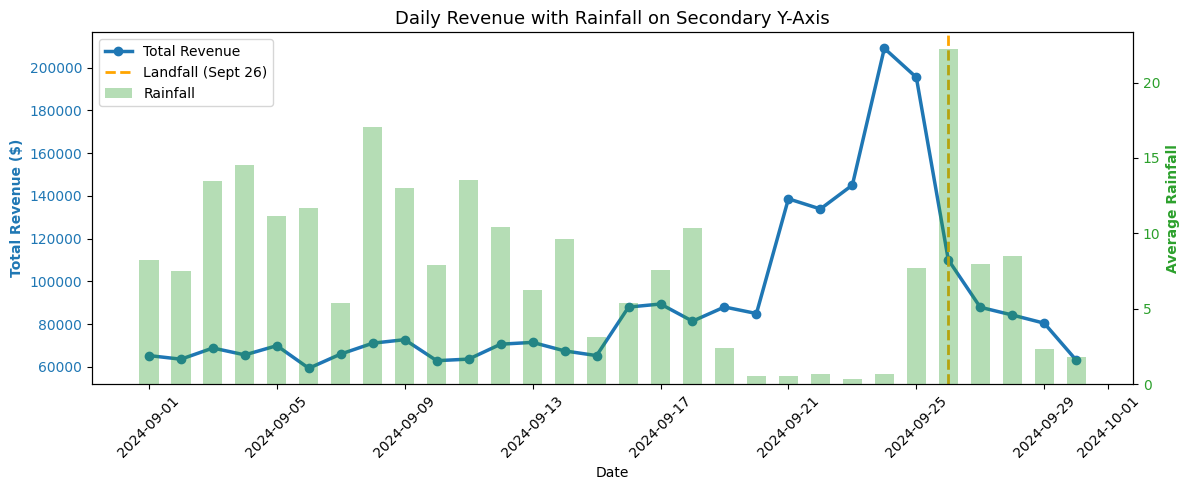

In [ ]:
# Investigate daily sales volume/revenue vs. rainfall and precipitation
daily_summary = weather_live.groupby('date').agg(
    total_revenue=('total_revenue', 'sum'),
    total_units=('total_units', 'sum'),
    avg_precipitation=('precipitation_sum', 'mean'),
    avg_windspeed=('windspeed_10m_max', 'mean')
).reset_index()

# Plot Chart 4
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Revenue (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Revenue ($)', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_revenue'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Revenue'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Rainfall (Bar Chart)
ax2 = ax1.twinx()  # Moves rainfall to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Rainfall', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_precipitation'],
    color=color_rain,
    alpha=0.35,  # Transparency so revenue line remains clearly visible
    width=0.6,
    label='Rainfall'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Daily Revenue with Rainfall on Secondary Y-Axis', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

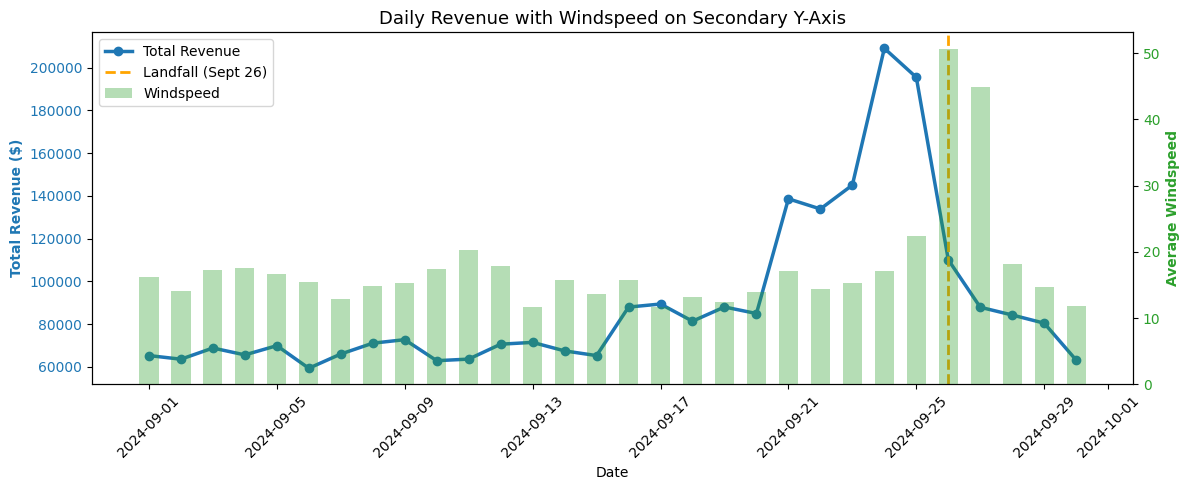

In [ ]:
# Plot Chart 5
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Revenue (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Revenue ($)', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_revenue'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Revenue'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Windspeed (Bar Chart)
ax2 = ax1.twinx()  # Moves Windspeed to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Windspeed', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_windspeed'],
    color=color_rain,
    alpha=0.35,  # Transparency so revenue line remains clearly visible
    width=0.6,
    label='Windspeed'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Daily Revenue with Windspeed on Secondary Y-Axis', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

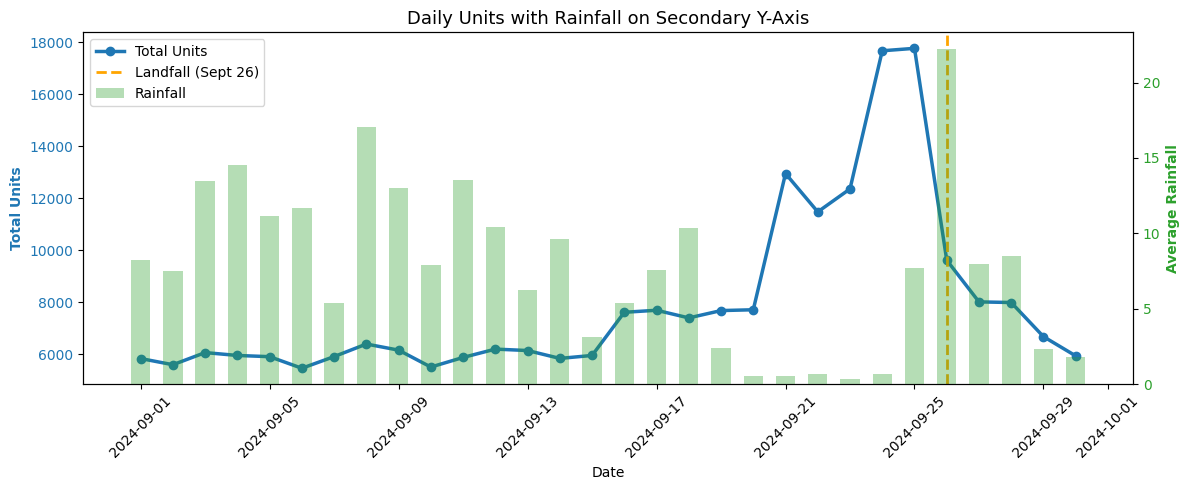

In [ ]:
# Plot Chart 6
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Units (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Units', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_units'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Units'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Rainfall (Bar Chart)
ax2 = ax1.twinx()  # Moves rainfall to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Rainfall', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_precipitation'],
    color=color_rain,
    alpha=0.35,  # Transparency so units line remains clearly visible
    width=0.6,
    label='Rainfall'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Daily Units with Rainfall on Secondary Y-Axis', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

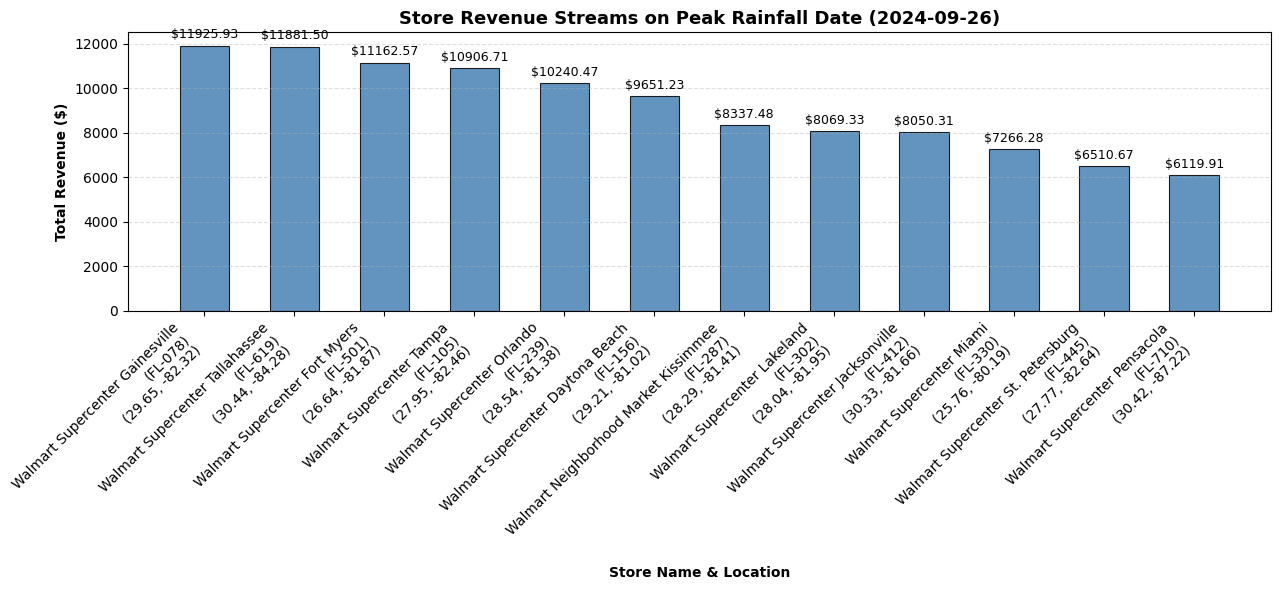

In [ ]:
peak_rain_idx = daily_summary['avg_precipitation'].idxmax()
peak_rain_date = daily_summary.loc[peak_rain_idx, 'date']
formatted_date = pd.to_datetime(peak_rain_date).strftime('%Y-%m-%d')

# 2. Filter for peak day
peak_day_df = weather_live[weather_live['date'] == peak_rain_date]

# 3. Aggregate revenue per store including store_name
store_rev = (
    peak_day_df.groupby(['store_id', 'store_name', 'latitude', 'longitude'])['total_revenue']
    .sum()
    .reset_index()
    .sort_values('total_revenue', ascending=False)
)

# Format X-axis labels: Store Name + ID + Coordinates
store_rev['location_label'] = store_rev.apply(
    lambda r: f"{r['store_name']}\n({r['store_id']})",
    axis=1
)

# 4. Plot
plt.figure(figsize=(13, 6))

bars = plt.bar(
    store_rev['location_label'],
    store_rev['total_revenue'],
    color='steelblue',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85,
    width=0.55
)

# Add exact revenue figures on top of each bar
plt.bar_label(bars, fmt='$%.2f', padding=3, fontsize=9)

plt.xlabel('Store Name & Location', fontweight='bold')
plt.ylabel('Total Revenue ($)', fontweight='bold')
plt.title(f'Store Revenue Streams on Peak Rainfall Date ({formatted_date})', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Analysis
Five questions, each with code, a chart, and a written answer.

###5.1 Demand surge
**Owner: Eli + Sophie (Chart)**

> Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

**Windows:** baseline = Sept 1–15 (flat, before the first rise on Sept 16); surge = Sept 19–25 (the 7 days before landfall on Sept 26).

               baseline_per_day  surge_per_day  pct_increase
category                                                    
Breakfast                  73.3          376.9         414.0
Emergency                 354.1         1006.4         184.0
Electronics                70.3          175.9         150.0
Alcohol                    61.5          138.9         126.0
Entertainment             101.6          228.6         125.0
Health                     42.3           95.0         124.0
Household                  85.1          176.3         107.0
Grocery                   171.1          306.6          79.0
Baby                       85.2          133.7          57.0
Snacks                     58.5           73.7          26.0


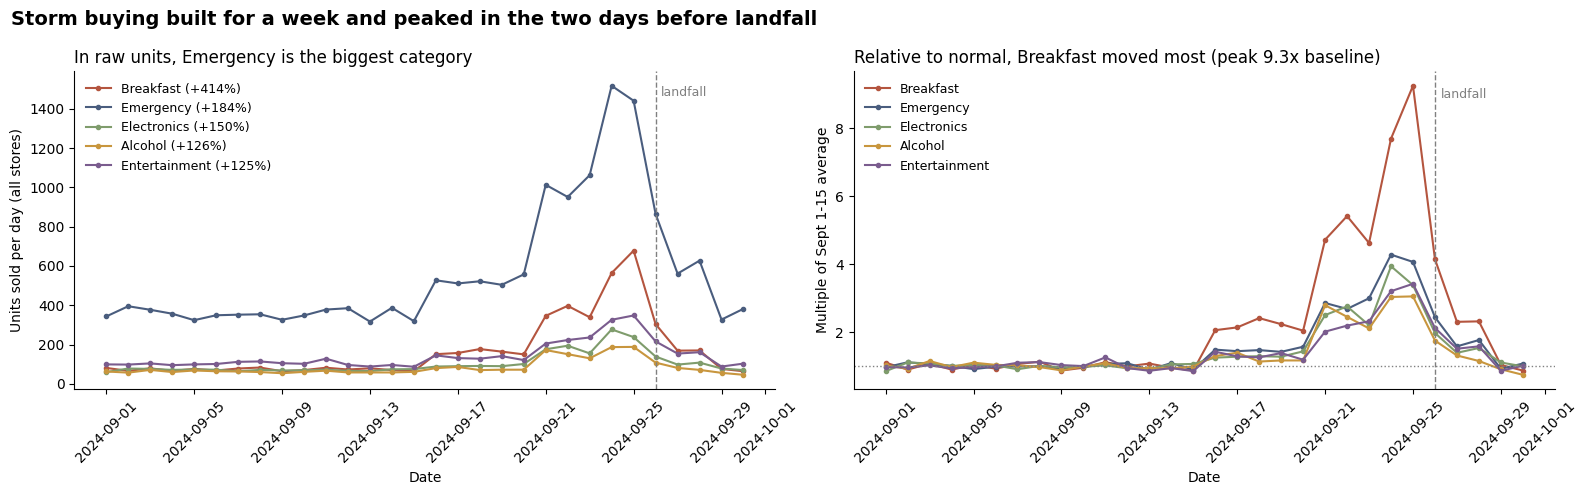

In [ ]:
# Only use rows that have a timestamp and aren't returns
t = txn[~txn['ts_missing'] & ~txn['is_return']]

# Total units sold each day for each category
by_cat = t.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')

# Normal days = Sept 1-15, storm week = Sept 19-25 (the 7 days before landfall)
base  = by_cat.loc['2024-09-01':'2024-09-15'].mean()
surge = by_cat.loc['2024-09-19':'2024-09-25'].mean()

# Compare the storm week to normal days for every category
summary = pd.DataFrame({
    'baseline_per_day': base.round(1),
    'surge_per_day':    surge.round(1),
    'pct_increase':     ((surge / base - 1) * 100).round(0),
}).sort_values('pct_increase', ascending=False)
print(summary)

# Keep the 5 categories that went up the most
top5 = summary.index[:5]
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#7a5c8e']

# Divide each category by its normal day, so 1.0 means a normal day
indexed = by_cat[top5] / base[top5]

# Left chart: actual units, right chart: compared to normal
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

for cat, color in zip(top5, colors):
    ax1.plot(by_cat.index, by_cat[cat], marker='o', ms=3, color=color,
             label=f"{cat} (+{summary.loc[cat, 'pct_increase']:.0f}%)")
    ax2.plot(indexed.index, indexed[cat], marker='o', ms=3, color=color, label=cat)

ax1.set_title('In raw units, Emergency is the biggest category', loc='left', fontsize=12)
ax1.set_ylabel('Units sold per day (all stores)')

ax2.axhline(1.0, ls=':', color='gray', lw=1)   # dotted line = a normal day
ax2.set_title(f"Relative to normal, {top5[0]} moved most "
              f"(peak {indexed[top5[0]].max():.1f}x baseline)", loc='left', fontsize=12)
ax2.set_ylabel('Multiple of Sept 1-15 average')

# Same landfall line, labels, and style on both charts
for ax in (ax1, ax2):
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=6), ax.get_ylim()[1] * 0.92),
                fontsize=9, color='gray')
    ax.set_xlabel('Date')
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

fig.suptitle('Storm buying built for a week and peaked in the two days before landfall',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q1 answer:**
Breakfast was the category that had the biggest surge moving 477% from 73 units per day to 377 units per day 7 days before landfall, at it's peak breakfast sold up to 9.3x its normal levels. The other top categories were Emergenecy, Electronics, Alcohol, and Entertainment. Emergency sales increased 184%, and by sheer volume was the largest sales category selling 650 additional units per day. All of them follow a similar timeline, creeping up around Sept 16 and peaking Sept 24-25 which is two days before landfall, and sharply falls off once the storm makes landfall on the 26th.

###5.2 The Pop-Tarts effect (SKU consolidation)
**Owner: Eli + Sophie (Chart)**

> After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

Pop-Tarts SKUs merged into PT-STRAW: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
unit totals unchanged after consolidation: OK
Pop-Tarts per day: normal (Sept 1-15) 73, storm week (Sept 19-25) 377, peak 678 on Sep 25


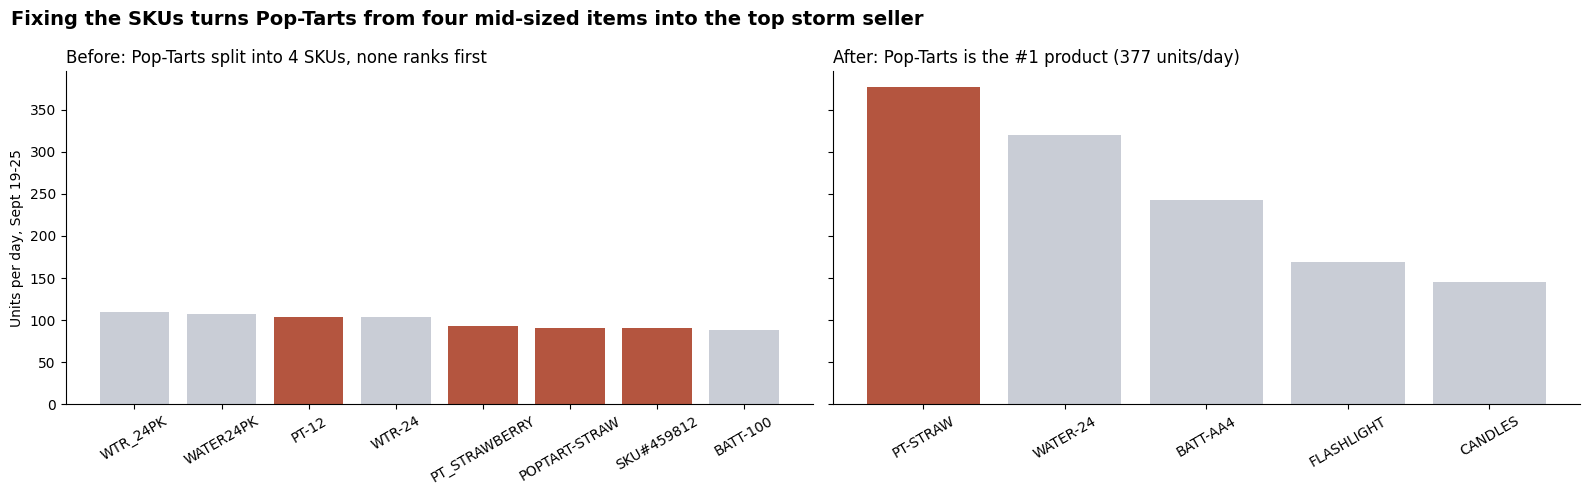

In [ ]:
# Only use rows that have a timestamp and aren't returns (same as Q1)
t = txn[~txn['ts_missing'] & ~txn['is_return']]

# The Pop-Tarts family: 4 raw SKUs that are really one product
pt_skus = sorted(k for k, v in SKU_TO_PRODUCT.items() if v == 'PT-STRAW')
print('Pop-Tarts SKUs merged into PT-STRAW:', pt_skus)

# Check: merging SKUs should not change the total units
assert t.groupby('sku')['quantity'].sum().sum() == t.groupby('product_id')['quantity'].sum().sum()
print('unit totals unchanged after consolidation: OK')

# True daily volume of Pop-Tarts after merging
pt_daily = t[t['product_id'] == 'PT-STRAW'].groupby('date')['quantity'].sum()
print(f"Pop-Tarts per day: normal (Sept 1-15) {pt_daily.loc[:'2024-09-15'].mean():.0f}, "
      f"storm week (Sept 19-25) {pt_daily.loc['2024-09-19':'2024-09-25'].mean():.0f}, "
      f"peak {pt_daily.max():.0f} on {pt_daily.idxmax():%b %d}")

# Storm week (7 days before landfall): average units per day
storm = t[(t['date'] >= '2024-09-19') & (t['date'] <= '2024-09-25')]
by_sku     = (storm.groupby('sku')['quantity'].sum() / 7).sort_values(ascending=False).head(8)
by_product = (storm.groupby('product_id')['quantity'].sum() / 7).sort_values(ascending=False).head(5)

# Left: what you see with raw SKUs, right: after merging into products
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), sharey=True)   # same scale so the sizes compare fairly

colors1 = ['#b4553f' if s in pt_skus else '#c9cdd6' for s in by_sku.index]
ax1.bar(by_sku.index, by_sku.values, color=colors1)
ax1.set_title('Before: Pop-Tarts split into 4 SKUs, none ranks first', loc='left', fontsize=12)
ax1.set_ylabel('Units per day, Sept 19-25')
ax1.tick_params(axis='x', rotation=30)

colors2 = ['#b4553f' if p == 'PT-STRAW' else '#c9cdd6' for p in by_product.index]
ax2.bar(by_product.index, by_product.values, color=colors2)
ax2.set_title(f"After: Pop-Tarts is the #1 product ({by_product['PT-STRAW']:.0f} units/day)",
              loc='left', fontsize=12)
ax2.tick_params(axis='x', rotation=30)

for ax in (ax1, ax2):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

fig.suptitle('Fixing the SKUs turns Pop-Tarts from four mid-sized items into the top storm seller',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Answer: Once all 4 SKU's for poptarts are combined into one product they actually sell 73 units on a normal day, 377 one day before the storm, and 678 on the Sept 25 peak. The uncleaned and matched data tells a very different story than the consolidated cleaned view. In the uncleaned set Pop-Tarts looks like ordinary items selling 90-103 units per day where none of the individual SKUs outrank water. In the cleaned set Pop Tarts are the number one product in the week, outselling water. Business decisions surrounding ordering, truck space and shelf space availability, and the forecasting would all differ if done on the individual rather than grouped SKU

###5.3 Weather correlation
**Owner: AJ + Sophie (Chart)**

> How do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

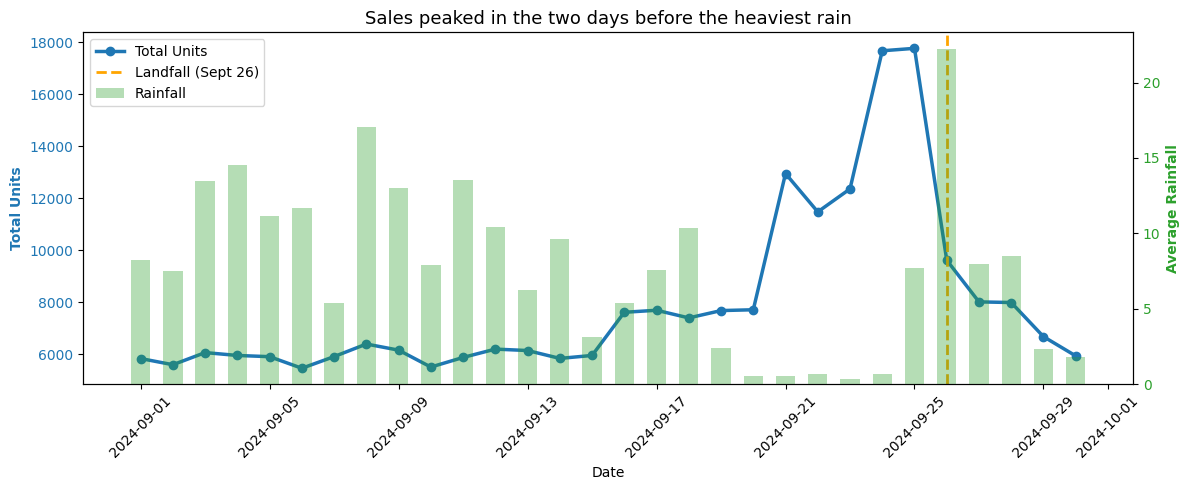

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Units (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Units', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_units'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Units'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Rainfall (Bar Chart)
ax2 = ax1.twinx()  # Moves rainfall to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Rainfall', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_precipitation'],
    color=color_rain,
    alpha=0.35,  # Transparency so units line remains clearly visible
    width=0.6,
    label='Rainfall'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Sales peaked in the two days before the heaviest rain', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

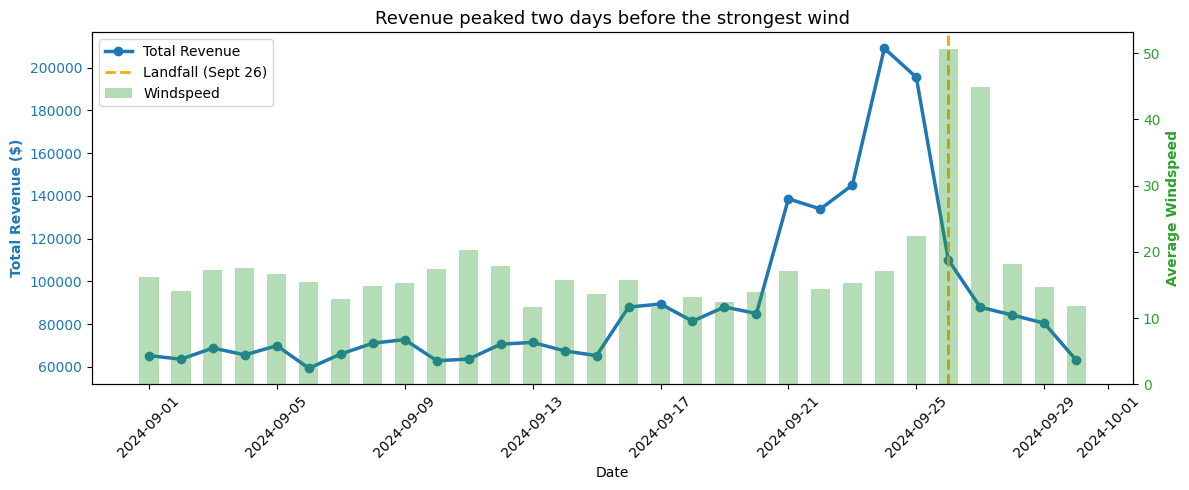

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Primary Y-Axis (Left): Total Revenue (Line Chart)
color_rev = '#1f77b4'  # Blue
ax1.set_xlabel('Date')
ax1.set_ylabel('Total Revenue ($)', color=color_rev, fontweight='bold')
line_rev = ax1.plot(
    daily_summary['date'],
    daily_summary['total_revenue'],
    color=color_rev,
    marker='o',
    linewidth=2.5,
    label='Total Revenue'
)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Secondary Y-Axis (Right): Windspeed (Bar Chart)
ax2 = ax1.twinx()  # Moves Windspeed to the secondary axis on the right
color_rain = '#2ca02c'  # Green
ax2.set_ylabel('Average Windspeed', color=color_rain, fontweight='bold')
bars_rain = ax2.bar(
    daily_summary['date'],
    daily_summary['avg_windspeed'],
    color=color_rain,
    alpha=0.35,  # Transparency so revenue line remains clearly visible
    width=0.6,
    label='Windspeed'
)
ax2.tick_params(axis='y', labelcolor=color_rain)

# Reference Line: Landfall Date
line_landfall = ax1.axvline(LANDFALL, color='orange', linestyle='--', linewidth=2, label='Landfall (Sept 26)')

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.title('Revenue peaked two days before the strongest wind', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

**Q3 answer:** There appears to be a detectable lag between the weather severity and weather indicators. Looking at wind speed and precipitation and merging based on date, both the revenue and the total units sold spike right before the worst of the weather hits. Both rainfall and windspeed appear to be accurate reactionary factors for the unit sold spike, meaning that they both accurately predict a storm. Refer to section above

The number of rows did not change when merged between the weather API data and the sales data, and zero NaN values were recorded. Refer to section 4.1 for same row values. Thus, data for each data at each store location was available.

###5.4 Store-level geographic patterns
**Owner: AJ + Sophie (Chart)**

> Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

                    city  miles_from_landfall  surge_multiple first_day_2x peak_day  transactions
store_id                                                                                         
FL-619       Tallahassee                 36.0            2.60       Sep 21   Sep 24          1981
FL-078       Gainesville                 96.0            2.37       Sep 22   Sep 25          2001
FL-412      Jacksonville                133.0            2.49       Sep 21   Sep 25          2028
FL-105             Tampa                169.0            2.53       Sep 21   Sep 25          2043
FL-445    St. Petersburg                175.0            2.45       Sep 21   Sep 24          2074
FL-156     Daytona Beach                180.0            2.41       Sep 21   Sep 24          2074
FL-302          Lakeland                182.0            2.49       Sep 21   Sep 25          2123
FL-239           Orlando                183.0            2.23       Sep 21   Sep 24          2010
FL-287         Kissi

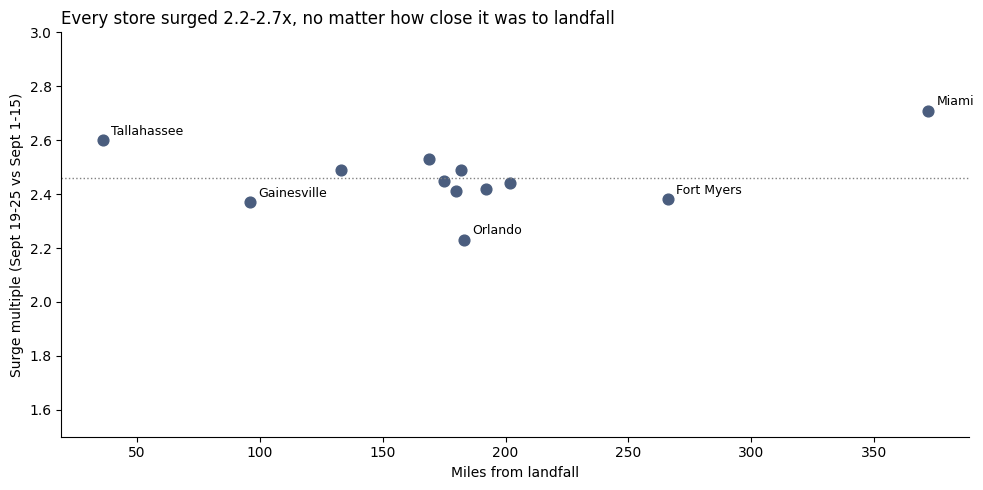

In [ ]:
t = txn[~txn['ts_missing'] & ~txn['is_return']]

# Units sold per day at each store
by_store = t.pivot_table(index='date', columns='store_id', values='quantity', aggfunc='sum')

# Surge multiple per store: storm week (Sept 19-25) vs normal days (Sept 1-15), same windows as Q1
base  = by_store.loc['2024-09-01':'2024-09-15'].mean()
surge = by_store.loc['2024-09-19':'2024-09-25'].mean()

# Timing: first day each store sold at least 2x its normal amount, and its busiest day
vs_normal = by_store / base
first_2x = vs_normal.loc['2024-09-16':].ge(2).idxmax()
peak_day = by_store.idxmax()

# Distance from each store to Helene's landfall (Big Bend coast near Perry, FL, approx. 30.07 N, 83.86 W)
LANDFALL_LAT, LANDFALL_LON = 30.07, -83.86
s = stores.set_index('store_id')
lat1, lon1 = np.radians(s['latitude']), np.radians(s['longitude'])
lat2, lon2 = np.radians(LANDFALL_LAT), np.radians(LANDFALL_LON)
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
miles = 2 * 3959 * np.arcsin(np.sqrt(a))   # haversine distance, earth radius in miles

store_summary = pd.DataFrame({
    'city': s['city'],
    'miles_from_landfall': miles.round(0),
    'surge_multiple': (surge / base).round(2),
    'first_day_2x': first_2x.dt.strftime('%b %d'),
    'peak_day': peak_day.dt.strftime('%b %d'),
    'transactions': t.groupby('store_id').size(),
}).sort_values('miles_from_landfall')
print(store_summary.to_string())
print('correlation, distance vs surge multiple:',
      round(store_summary['miles_from_landfall'].corr(store_summary['surge_multiple']), 2),
      f'(n = {len(store_summary)} stores)')

# Scatter: one dot per store; label only the closest, farthest, highest and lowest (the table has the rest)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(store_summary['miles_from_landfall'], store_summary['surge_multiple'], s=60, color='#4a5d7e')
for city in ['Tallahassee', 'Gainesville', 'Orlando', 'Fort Myers', 'Miami']:
    row = store_summary[store_summary['city'] == city].iloc[0]
    ax.annotate(city, (row['miles_from_landfall'], row['surge_multiple']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)
ax.axhline(store_summary['surge_multiple'].mean(), ls=':', color='gray', lw=1)   # average of all stores
ax.set_ylim(1.5, 3.0)
ax.set_title('Every store surged 2.2-2.7x, no matter how close it was to landfall', loc='left', fontsize=12)
ax.set_xlabel('Miles from landfall')
ax.set_ylabel('Surge multiple (Sept 19-25 vs Sept 1-15)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Q4 Answer:** Our data supports the theory that there was an insignficant difference in surge pattern between the individual stores. According to our graph above, each store seems to more than double their units sold with no evident correlation with "Miles from Landfall". Interestingly, Miami had the largest surge despite being the furtherst from landfall. This data suggests that population size had a larger impact on individual store surge rather than distance from landfall.

###5.5 Signal vs. artifact
**Owner: Sophie**

> The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

In [ ]:
# Step 1 : surge for every category in the database, as a 7-day average and as the single peak day
query = """
WITH clean AS (
    SELECT CASE WHEN length(date) = 8
                THEN substr(date, 1, 4) || '-' || substr(date, 5, 2) || '-' || substr(date, 7, 2)
                ELSE date END AS day,          -- dates come in two formats
           category, total_units
    FROM daily_sales_summary
),
daily AS (
    SELECT day, category, SUM(total_units) AS units
    FROM clean GROUP BY day, category
)
SELECT category,
       AVG(CASE WHEN day <= '2024-09-15' THEN units END)                  AS normal_per_day,
       AVG(CASE WHEN day BETWEEN '2024-09-19' AND '2024-09-25' THEN units END) AS storm_week_per_day,
       MAX(units)                                                         AS peak_day_units
FROM daily
GROUP BY category
"""
db = pd.read_sql_query(query, conn).set_index('category')
db['week_pct']     = ((db['storm_week_per_day'] / db['normal_per_day'] - 1) * 100).round(0)
db['peak_day_pct'] = ((db['peak_day_units'] / db['normal_per_day'] - 1) * 100).round(0)
print(db.sort_values('week_pct', ascending=False).round(1).to_string())

               normal_per_day  storm_week_per_day  peak_day_units  week_pct  peak_day_pct
category                                                                                 
Breakfast               595.6              1999.6          3371.0     236.0         466.0
Emergency               550.8              1556.6          2267.5     183.0         312.0
Entertainment           568.5              1394.5          2113.0     145.0         272.0
Health                  573.2              1252.9          1831.0     119.0         219.0
Alcohol                 601.5              1275.4          1790.0     112.0         198.0
Household               588.0              1198.9          1738.0     104.0         196.0
Electronics             608.0              1200.6          1864.0      97.0         207.0
Grocery                 584.4               949.4          1262.0      62.0         116.0
Baby                    601.2               927.2          1365.5      54.0         127.0
Snacks    

**Step 1 Finding:** in the database, Entertainment rose +145% over the 7 days before landfall, but +272% on its single busiest day (Sept 24). The +250% figure only appears if you look at the peak day.

In [ ]:
# Step 2: cross-check Entertainment against the transactions, product by product
t = txn[~txn['ts_missing'] & ~txn['is_return']]
ent = t[t['category'] == 'Entertainment']
print('raw category labels that became Entertainment:', sorted(ent['category_raw'].unique()))
print('products in Entertainment:', sorted(ent['product'].unique()))

def week_pct(daily):
    return round((daily.loc['2024-09-19':'2024-09-25'].mean() / daily.loc[:'2024-09-15'].mean() - 1) * 100)

ent_daily = ent.groupby('date')['quantity'].sum()
print('\nEntertainment, transactions, 7-day avg:', week_pct(ent_daily), '%')
for prod, g in ent.groupby('product'):
    print(f'  {prod}: {week_pct(g.groupby("date")["quantity"].sum())} %')

# Data problems in the database's Entertainment rows (flagged during cleaning)
ent_db = sales[sales['category'] == 'Entertainment']
print('\nDB Entertainment rows with fractional units:', ent_db['units_fractional'].sum(),
      '| negative revenue:', ent_db['revenue_negative'].sum(), '| out of', len(ent_db))

raw category labels that became Entertainment: ['ENTERTAINMENT', 'Entertainment', 'Games & Entertainment', 'entertainment']
products in Entertainment: ['Monopoly Board Game', 'Playing Cards']

Entertainment, transactions, 7-day avg: 125 %
  Monopoly Board Game: 160 %
  Playing Cards: 99 %

DB Entertainment rows with fractional units: 6 | negative revenue: 4 | out of 360


**Step 2 Finding:** The transaction data shows the same thing. Entertainment went up 125% that week, which is pretty close to the database. The category only has two products, Monopoly (+160%) and playing cards (+99%), so board games were the bigger part of it. The four different labels (like “Games & Entertainment”) are just different spellings of the same category. Only 10 out of 360 database rows had weird values, which isn’t enough to cause the increase.

avg units on hand, Sept 15-20: 134 | Sept 21-25: 33


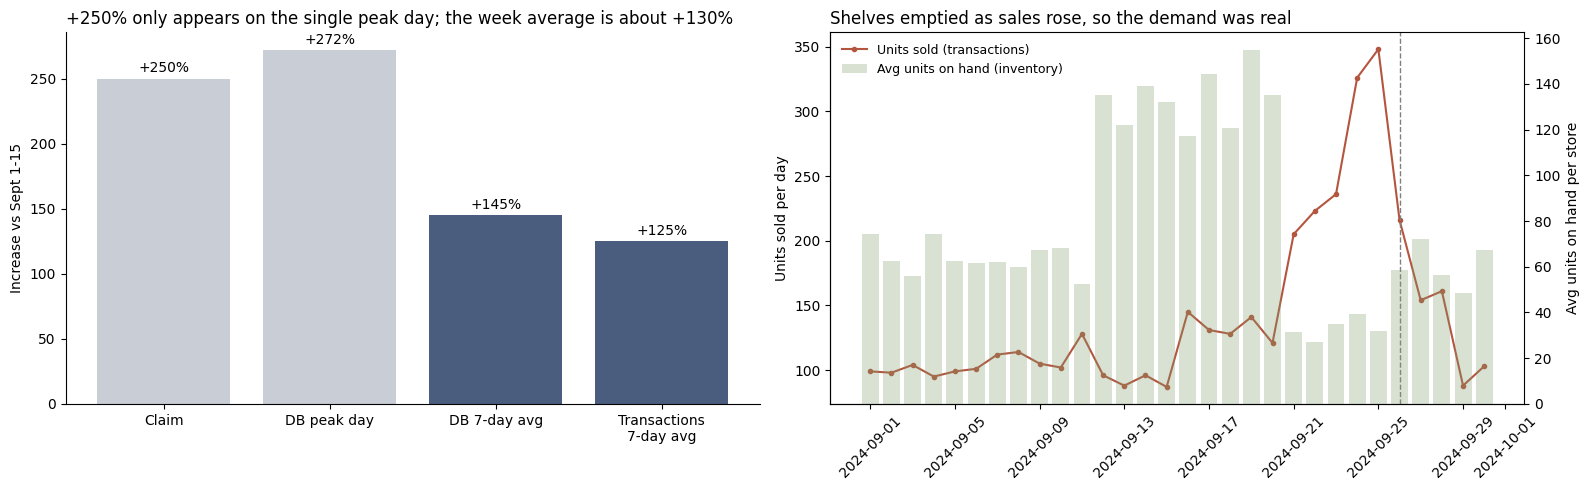

In [ ]:
# Step 3: did board game and card stock actually go down when sales went up?
inv_query = """
SELECT date, AVG(units_on_hand) AS avg_on_hand
FROM inventory_levels
WHERE sku IN ('BG-MONO', 'MONOPOLY-01', 'GAME-MONO', 'CARDS-01', 'PLAYCARD-STD')
GROUP BY date
ORDER BY date
"""
ent_inv = pd.read_sql_query(inv_query, conn)
ent_inv['date'] = pd.to_datetime(ent_inv['date'])
ent_inv = ent_inv.set_index('date')['avg_on_hand']
print('avg units on hand, Sept 15-20:', round(ent_inv.loc['2024-09-15':'2024-09-20'].mean()),
      '| Sept 21-25:', round(ent_inv.loc['2024-09-21':'2024-09-25'].mean()))

# Plot: left chart = how big the surge looks depending on how people measure it, right chart = sales vs stock
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

labels = ['Claim', 'DB peak day', 'DB 7-day avg', 'Transactions\n7-day avg']
values = [250, db.loc['Entertainment', 'peak_day_pct'], db.loc['Entertainment', 'week_pct'], week_pct(ent_daily)]
ax1.bar(labels, values, color=['#c9cdd6', '#c9cdd6', '#4a5d7e', '#4a5d7e'])
for i, v in enumerate(values):
    ax1.text(i, v + 5, f'+{v:.0f}%', ha='center', fontsize=10)
ax1.set_title('+250% only appears on the single peak day; the week average is about +130%', loc='left', fontsize=12)
ax1.set_ylabel('Increase vs Sept 1-15')

ax2.plot(ent_daily.index, ent_daily.values, marker='o', ms=3, color='#b4553f', label='Units sold (transactions)')
ax2.set_ylabel('Units sold per day')
ax3 = ax2.twinx()
ax3.bar(ent_inv.index, ent_inv.values, color='#7f9c6c', alpha=0.3, width=0.8, label='Avg units on hand (inventory)')
ax3.set_ylabel('Avg units on hand per store')
ax2.axvline(LANDFALL, ls='--', color='gray', lw=1)
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')
ax2.set_title('Shelves emptied as sales rose, so the demand was real', loc='left', fontsize=12)
ax2.tick_params(axis='x', rotation=45)

for ax in (ax1, ax2):
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Step 3 Finding:** We also checked the inventory table. Stores had about 134 board games and cards on hand per store during Sept 15-20, but only about 33 during Sept 21-25, right when sales jumped. If the surge was just a data mistake, the shelves wouldn’t have emptied like this, so the demand was real. (Inventory dropped for the other categories too, so this shows board games acted like real storm demand, not that they were special.)

**Q5 answer:** The board game surge is a real demand signal, but +250% overstates it. That number only appears on the single peak day, while the full storm week shows about +125%, mostly driven by Monopoly. The two data sources agree, the data errors are too small to matter, and the shelves emptied, so it isn't an artifact. Walmart should stock extra board games for the next storm, sized to the week average rather than +250%.

## 6. Recommendation for Walmart leadership

## 7. Reflection
Each team member contributes. One solid paragraph minimum per question.

**1. Data Quality Impact**
> Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?

_TODO_

**2. ETL Trade-offs**
> You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?

_TODO_

**3. Pipeline Trust**
> The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?

_TODO_

**4. Business vs. Data**
> For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?

_TODO_

**5. Team Collaboration**
> How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?

_TODO_

### The data you are getting

Five files, in the `data/` folder next to this notebook.

| File | What it is | Size |
|---|---|---|
| `walmart_transactions.csv` | Point-of-sale records from Florida stores, September 2024 | about 25,000 rows |
| `store_locations.csv` | Store details: city, coordinates, region | about 14 rows |
| `product_catalog.csv` | The master list of products and SKUs | about 45 rows |
| `distribution_centers.csv` | Distribution center capacity and shipping cost | 5 rows |
| `inventory_and_sales.db` | SQLite database with `daily_sales_summary` and `inventory_levels` | about 7,900 rows across both tables |

Every file has quality problems, and finding them is part of the work. The brief lists what to expect:

- duplicate records
- missing values written several ways: empty, `NULL`, `N/A`, NaN
- dates and times in different formats
- the same product under several SKUs and names
- inconsistent capitalization and spacing
- category names that don't match
- numbers stored as text, and prices with `$` signs
- negative quantities
- store ids written different ways across files
- weather data in a different timezone than the sales data

You will profile the transactions file in a few minutes. The database matters mostly for Question 5.

In [ ]:
import sqlite3

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

# Get data from repository
REPO_PATH = '/content/Walmart-Project-1-/'
catalog_data = pd.read_csv(REPO_PATH + 'data/product_catalog.csv')
distribution_center = pd.read_csv(REPO_PATH + 'data/distribution_centers.csv')
walmart_transactions = pd.read_csv(REPO_PATH + 'data/walmart_transactions.csv')
store_locations = pd.read_csv(REPO_PATH + 'data/store_locations.csv')

# Read db into pandas
conn = sqlite3.connect(REPO_PATH + 'data/inventory_and_sales.db')
cursor = conn.cursor()

print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))
pd.read_sql_query('PRAGMA table_info(inventory_levels)', conn)

                  name
0  daily_sales_summary
1     inventory_levels


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,sku,TEXT,0,None,0
3,3,units_on_hand,INTEGER,0,None,0
4,4,units_on_order,INTEGER,0,None,0
5,5,reorder_point,INTEGER,0,None,0
